# Combined melting-point dataset analysis

This notebook describes the final combined dataset, `outputs/combined_data.parquet` (written by `2_stereo_cleanup.ipynb`). It reads that file only and writes nothing, so editing or rerunning it does not affect any downstream stage.

1. **Summary table:** compounds, low/high MP counts and MP statistics for the combined dataset and each source.
2. **MP distributions:** the combined dataset and the four sources on one axis.
3. **Source overlap:** a pairwise overlap heatmap, plus the table of exact source combinations.

**What "Source *s*" means here.** Each final compound lists, in its `Source` column, the sources whose MP values were accepted for its consensus MP. Source *s* is the set of final compounds that list *s*, plotted at their consensus MP. It is therefore the source's contribution to the final dataset, after curation, consensus and the stereo clean-up, not the source's raw table.

High MP is defined as **MP ≥ 250 °C**; low MP is MP < 250 °C.

**Saving figures:** each figure cell has a commented `savefig` line. Uncomment it (and the `mkdir` line) after previewing the figure.

In [1]:
%config InlineBackend.figure_format = 'retina'

from pathlib import Path
from itertools import combinations

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter
from IPython.display import display

data_dir_candidates = [Path.cwd(), Path.cwd() / '0_data', Path.cwd().parent / '0_data']
DATA_DIR = next((path.resolve() for path in data_dir_candidates
                 if (path / 'outputs' / 'combined_data.parquet').is_file()), None)
if DATA_DIR is None:
    raise FileNotFoundError('Could not find 0_data/outputs/combined_data.parquet. '
                            'Run this notebook from the repository root or from 0_data.')

OUTPUT_DIR = DATA_DIR / 'outputs'
COMBINED_DATA_PATH = OUTPUT_DIR / 'combined_data.parquet'
FIGURE_DIR = OUTPUT_DIR / 'figures'  # only used by the commented savefig lines

SOURCES = [1, 2, 3, 4]
SOURCE_NAMES = {  # labels used in tables and figures; edit freely
    1: 'Source 1',
    2: 'Source 2',
    3: 'Source 3',
    4: 'Source 4',
}
SOURCE_REFERENCES = {  # for the summary table only
    1: 'ChemXplore (Marimuthu, 2025)',
    2: 'EGNN (Huang, 2025)',
    3: 'PATENTS/OCHEM (Tetko, 2016)',
    4: 'Bradley (Austermeier, 2025)',
}
SOURCE_COLORS = {1: '#477C9B', 2: '#83A891', 3: '#CA806B', 4: '#7776B3'}  # palette used in stages 4-5
COMBINED_NAME = 'Combined'
COMBINED_COLOR = '#B8C1CC'
HIGH_MP_THRESHOLD_C = 250.0
MP_MIN_C, MP_MAX_C = 0.0, 500.0  # the curation range used in 1_combine_data.ipynb
PANEL_LABEL_FONTSIZE = 14  # same as the panel labels in stages 4 and 5

combined_data = pd.read_parquet(COMBINED_DATA_PATH, columns=['SMILES', 'MP', 'Source'])
membership = combined_data['Source'].map(lambda values: tuple(sorted(int(value) for value in values)))

assert combined_data['SMILES'].is_unique
assert combined_data['MP'].between(MP_MIN_C, MP_MAX_C).all()
assert membership.map(len).gt(0).all()
assert membership.map(lambda values: set(values) <= set(SOURCES)).all()

# One boolean column per source: does this final compound list that source?
in_source = pd.DataFrame({source: membership.map(lambda values, s=source: s in values)
                          for source in SOURCES})
print(f'Final compounds: {len(combined_data):,}')

Final compounds: 277,134


## Summary by dataset

`Unique_to_source` counts compounds supported by that source alone. Sources overlap, so the source rows do not add up to the combined row.

In [2]:
def describe(mp, name, reference, unique=None):
    high = int(mp.ge(HIGH_MP_THRESHOLD_C).sum())
    return {
        'Dataset': name, 'Reference': reference, 'Compounds': len(mp),
        'Percent_of_combined': 100 * len(mp) / len(combined_data),
        'Unique_to_source': unique,
        'Low_MP': len(mp) - high, 'High_MP': high, 'High_MP_percent': 100 * high / len(mp),
        'Median_MP_C': mp.median(), 'Min_MP_C': mp.min(), 'Max_MP_C': mp.max(),
    }

summary_rows = [describe(combined_data['MP'], COMBINED_NAME, 'This work')]
for source in SOURCES:
    summary_rows.append(describe(
        combined_data.loc[in_source[source], 'MP'], SOURCE_NAMES[source], SOURCE_REFERENCES[source],
        unique=int(membership.map(lambda values, s=source: values == (s,)).sum()),
    ))
dataset_summary = pd.DataFrame(summary_rows)
dataset_summary['Unique_to_source'] = dataset_summary['Unique_to_source'].astype('Int64')
display(dataset_summary.round(1))

,Dataset,Reference,Compounds,Percent_of_combined,Unique_to_source,Low_MP,High_MP,High_MP_percent,Median_MP_C,Min_MP_C,Max_MP_C
0,Combined,This work,277134,100.0,<NA>,255724,21410,7.7,147.5,0.0,492.5
1,Source 1,"ChemXplore (Marimuthu, 2025)",4604,1.7,573,4363,241,5.2,96.0,0.0,437.3
2,Source 2,"EGNN (Huang, 2025)",208580,75.3,2781,195058,13522,6.5,147.0,0.0,481.0
3,Source 3,"PATENTS/OCHEM (Tetko, 2016)",271995,98.1,63688,251037,20958,7.7,147.5,0.0,492.5
4,Source 4,"Bradley (Austermeier, 2025)",15646,5.6,868,14893,753,4.8,116.2,0.0,492.5


## MP distributions: combined dataset and sources

Each dataset is drawn as a line histogram with 10 °C bins. The y-axis is the **percentage of that dataset's compounds** in each bin, so datasets of very different size can be compared by shape; each dataset's n is in the summary table above and on the overlap heatmap. The combined dataset is the shaded area. Bins include their left edge, so compounds at exactly 250 °C fall in the 250–260 °C bin, on the high-MP side of the dashed line.

The combined and Source 3 curves nearly coincide because about 98% of the final compounds are supported by Source 3.

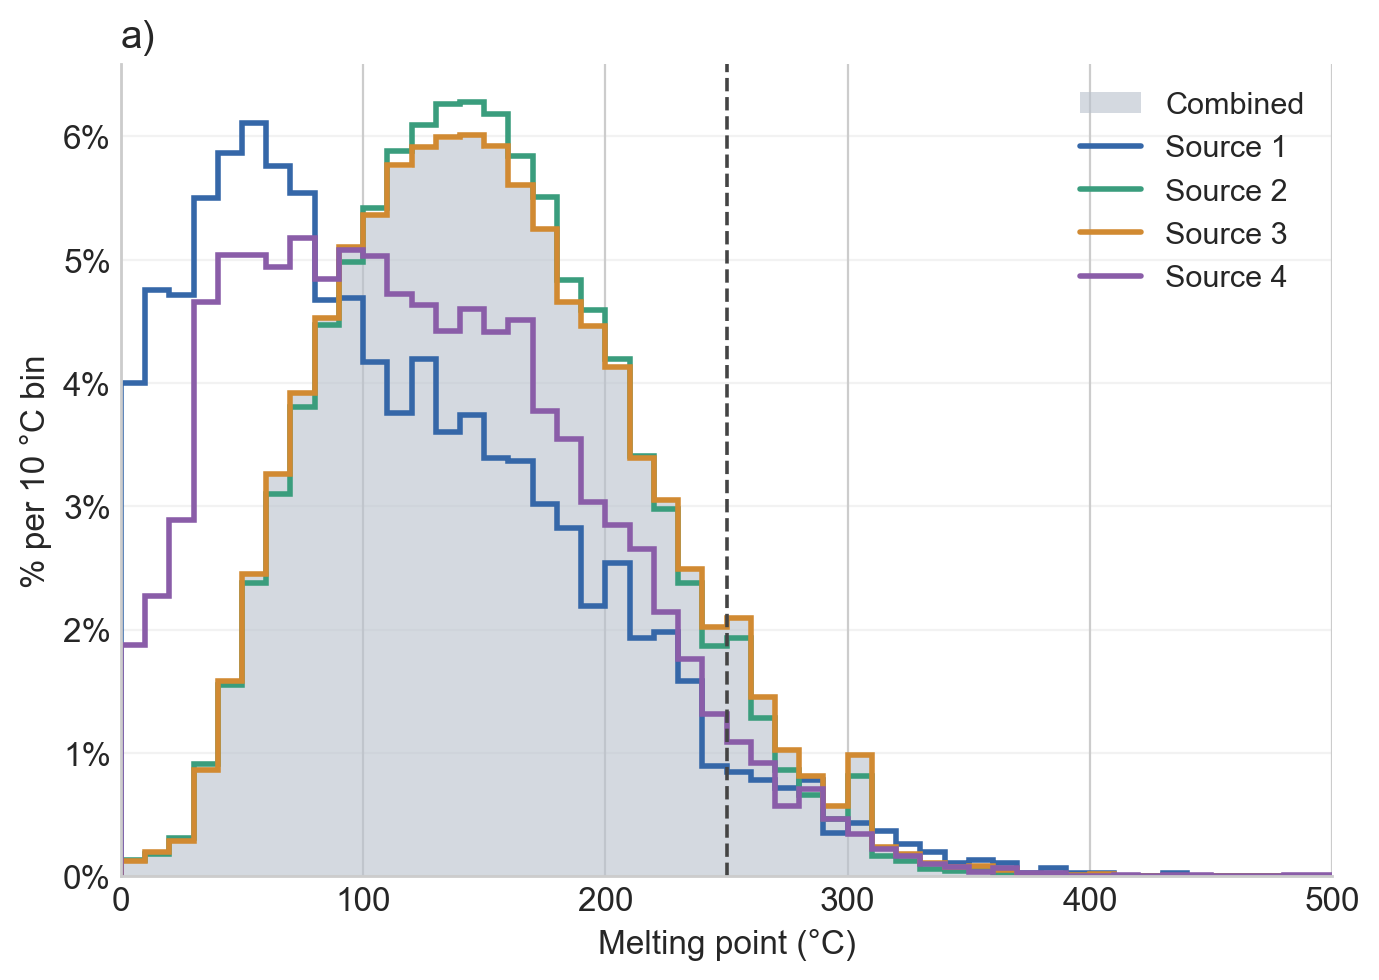

In [69]:
BIN_WIDTH_C = 10
DIST_FIGSIZE = (7, 5)
DIST_AXIS_LABEL_FONTSIZE = 12
DIST_TICK_FONTSIZE = 12
DIST_LEGEND_FONTSIZE = 11
DIST_TITLE = ''  # set a string to show a title
DIST_PANEL_LABEL = 'a)'  # set to '' to hide

bin_edges = np.arange(MP_MIN_C, MP_MAX_C + BIN_WIDTH_C, BIN_WIDTH_C)

def percent_per_bin(mp):
    counts, _ = np.histogram(mp, bins=bin_edges)
    return 100 * counts / len(mp)

fig, ax = plt.subplots(figsize=DIST_FIGSIZE)
ax.stairs(percent_per_bin(combined_data['MP']), bin_edges, fill=True, color=COMBINED_COLOR,
          alpha=0.6, label=COMBINED_NAME)
for source in SOURCES:
    mp = combined_data.loc[in_source[source], 'MP']
    ax.stairs(percent_per_bin(mp), bin_edges, color=SOURCE_COLORS[source], linewidth=2,
              label=SOURCE_NAMES[source])
ax.axvline(HIGH_MP_THRESHOLD_C, color='#444444', linestyle='--', linewidth=1.3)  # 250 °C threshold; explained in the caption

ax.set_xlim(MP_MIN_C, MP_MAX_C)
ax.set_ylim(bottom=0)
ax.set_xlabel('Melting point (°C)', fontsize=DIST_AXIS_LABEL_FONTSIZE)
ax.set_ylabel(f'% per {BIN_WIDTH_C} °C bin', fontsize=DIST_AXIS_LABEL_FONTSIZE)
ax.yaxis.set_major_formatter(PercentFormatter(decimals=0))
ax.tick_params(labelsize=DIST_TICK_FONTSIZE)
ax.spines[['top', 'right']].set_visible(False)
ax.grid(axis='y', alpha=0.25)
ax.set_axisbelow(True)
ax.legend(fontsize=DIST_LEGEND_FONTSIZE, frameon=False, loc='upper right')
if DIST_TITLE:
    ax.set_title(DIST_TITLE, fontsize=DIST_AXIS_LABEL_FONTSIZE + 2)
if DIST_PANEL_LABEL:
    ax.set_title(DIST_PANEL_LABEL, loc='left', fontsize=PANEL_LABEL_FONTSIZE)
fig.tight_layout()
# FIGURE_DIR.mkdir(exist_ok=True)
# fig.savefig(FIGURE_DIR / 'mp_distribution_combined_and_sources.png', dpi=300, bbox_inches='tight')
plt.show()

## Source overlap

**Heatmap.** The cell in row *i* and column *j* is the proportion of source *i*'s compounds that are also supported by source *j*. The matrix is not symmetric: for example, almost all of Source 2 is in Source 3, but a smaller share of Source 3 is in Source 2. Each axis label gives the source's size (n), and the grey diagonal gives the proportion of that source's compounds that no other source supports.

**Table.** `exact_combinations` lists every exact combination of sources (each compound counted once, in its one combination), for the SI.

In [4]:
pairwise_rows = []
for row_source in SOURCES:
    for column_source in SOURCES:
        shared = int((in_source[row_source] & in_source[column_source]).sum())
        pairwise_rows.append({'Row_source': row_source, 'Column_source': column_source,
                              'Shared': shared,
                              'Percent_of_row_source': 100 * shared / int(in_source[row_source].sum())})
pairwise_overlap = pd.DataFrame(pairwise_rows)
overlap_percent = pairwise_overlap.pivot(index='Row_source', columns='Column_source',
                                         values='Percent_of_row_source')
overlap_count = pairwise_overlap.pivot(index='Row_source', columns='Column_source', values='Shared')

exact_combinations = (
    membership.value_counts().rename_axis('Sources').reset_index(name='Compounds')
    .assign(Combination=lambda frame: frame['Sources'].map(lambda values: ' & '.join(map(str, values))),
            N_sources=lambda frame: frame['Sources'].map(len),
            Percent_of_combined=lambda frame: 100 * frame['Compounds'] / len(combined_data))
    [['Combination', 'N_sources', 'Compounds', 'Percent_of_combined']]
)
assert exact_combinations['Compounds'].sum() == len(combined_data)
display(exact_combinations.round(2))
multi_source = int(membership.map(len).gt(1).sum())
print(f'Compounds supported by more than one source: {multi_source:,} '
      f'({100 * multi_source / len(combined_data):.1f}% of the combined dataset)')

,Combination,N_sources,Compounds,Percent_of_combined
0,2 & 3,2,193987,70.00
1,3,1,63688,22.98
2,2 & 3 & 4,3,7768,2.80
3,1 & 2 & 3 & 4,4,2887,1.04
4,2,1,2781,1.00
5,3 & 4,2,2764,1.00
6,4,1,868,0.31
7,2 & 4,2,674,0.24
8,1,1,573,0.21
9,1 & 3 & 4,3,540,0.19


Compounds supported by more than one source: 209,224 (75.5% of the combined dataset)


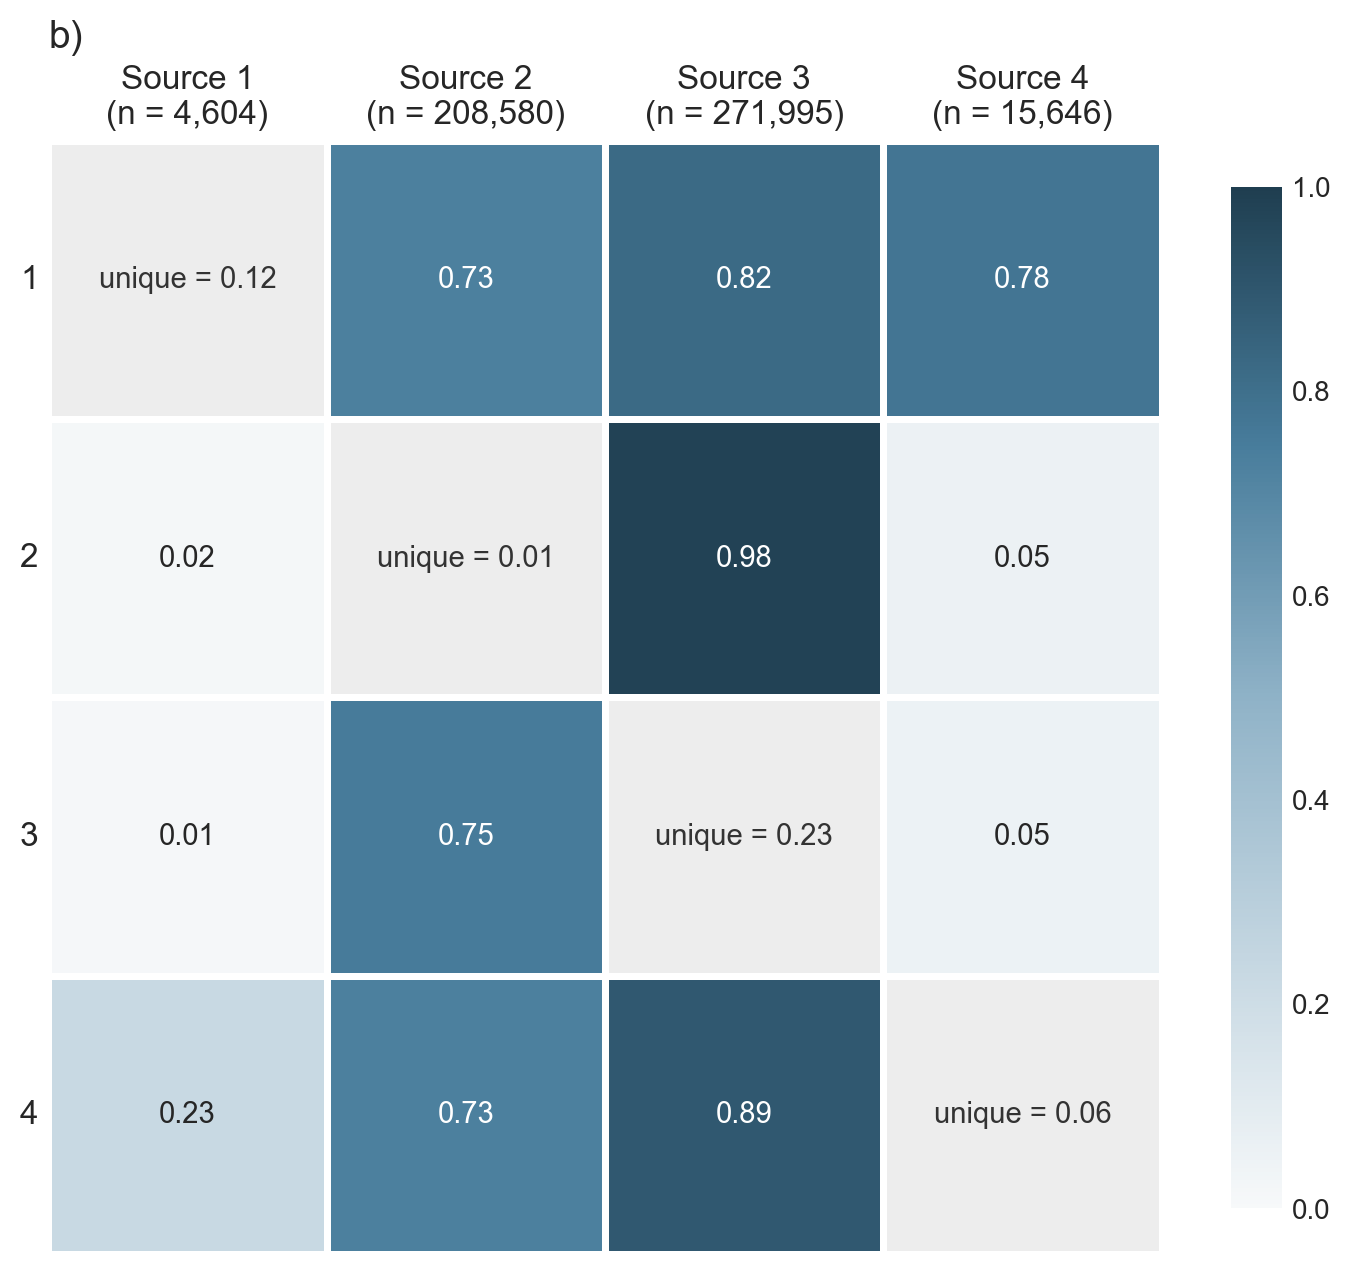

In [70]:
import seaborn as sns
from matplotlib.colors import LinearSegmentedColormap

OVERLAP_FIGSIZE = (7.4, 6.8)
# Single-hue ramp built on the palette blue (#477C9B) used in stages 4-5; it darkens
# mainly above 0.75 so the high proportions (0.73-0.98) stay distinguishable.
OVERLAP_CMAP = LinearSegmentedColormap.from_list(
    'palette_blue', [(0.0, '#F7F9FA'), (0.5, '#8FB2C7'), (0.75, '#477C9B'), (1.0, '#1F3E50')])
OVERLAP_CELL_FONTSIZE = 10.5
OVERLAP_TICK_FONTSIZE = 12
DIAGONAL_COLOR = '#EDEDED'
DIAGONAL_TEXT_COLOR = '#333333'
OVERLAP_DECIMALS = 2  # decimals shown in each cell
OVERLAP_PANEL_LABEL = 'b)'  # set to '' to hide

count_frame = overlap_count.loc[SOURCES, SOURCES]
column_labels = [f'{SOURCE_NAMES[source]}\n(n = {count_frame.loc[source, source]:,})' for source in SOURCES]  # n on its own line
row_labels = [str(source) for source in SOURCES]  # source and n are already given on the top axis
proportion_frame = overlap_percent.loc[SOURCES, SOURCES].astype(float) / 100
diagonal_mask = np.eye(len(SOURCES), dtype=bool)  # the diagonal is drawn separately below

with sns.axes_style('white'):
    fig, ax = plt.subplots(figsize=OVERLAP_FIGSIZE)
    ax.set_facecolor(DIAGONAL_COLOR)  # shows through the masked diagonal cells
    sns.heatmap(
        proportion_frame, mask=diagonal_mask, cmap=OVERLAP_CMAP, vmin=0, vmax=1,
        annot=True, fmt=f'.{OVERLAP_DECIMALS}f', annot_kws={'fontsize': OVERLAP_CELL_FONTSIZE},
        linewidths=2.5, linecolor='white', square=True,
        xticklabels=column_labels, yticklabels=row_labels, ax=ax,
        cbar_kws={'shrink': 0.82},
    )
    for position, source in enumerate(SOURCES):
        unique = int(membership.map(lambda values: values == (source,)).sum())
        unique_proportion = unique / count_frame.loc[source, source]
        ax.text(position + 0.5, position + 0.5, f'unique = {unique_proportion:.{OVERLAP_DECIMALS}f}',
                ha='center', va='center', fontsize=OVERLAP_CELL_FONTSIZE, color=DIAGONAL_TEXT_COLOR)

    ax.xaxis.tick_top()
    ax.xaxis.set_label_position('top')
    ax.set_xlabel('')
    ax.set_ylabel('')
    ax.tick_params(length=0, labelsize=OVERLAP_TICK_FONTSIZE)
    plt.setp(ax.get_yticklabels(), rotation=0)
    if OVERLAP_PANEL_LABEL:
        ax.set_title(OVERLAP_PANEL_LABEL, loc='left', fontsize=PANEL_LABEL_FONTSIZE)
    colorbar = ax.collections[0].colorbar
    colorbar.ax.tick_params(labelsize=OVERLAP_TICK_FONTSIZE - 2, length=0)
    colorbar.outline.set_visible(False)
    fig.tight_layout()
    # FIGURE_DIR.mkdir(exist_ok=True)
    # fig.savefig(FIGURE_DIR / 'source_overlap_heatmap.png', dpi=300, bbox_inches='tight')
    plt.show()